# Practical 3: Bank Customer Churn Prediction

**Aim:** Given bank customer details, build a neural network classifier to predict whether the customer will leave (`1`) or stay (`0`).

**Dataset:** `Churn_Modelling.csv` from the Kaggle Bank Customer Churn Modeling dataset.

**Assignment steps**
1. Read the dataset.
2. Separate features and target, then split into training and testing sets.
3. Normalize the training and testing data.
4. Build a neural network and improve it.
5. Print accuracy and confusion matrix.

**Note:** The dataset provides the `Exited` label, but no dates to verify an exact six-month period. This practical predicts the provided churn label.

## Cell 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

## Cell 2: Read the Dataset

In [2]:
df = pd.read_csv("Churn_Modelling.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4         790

## Cell 3: Separate Features and Target

In [3]:
# Remove columns that do not help predict customer churn
X = df.drop(["RowNumber", "CustomerId", "Surname", "Exited"], axis=1)
y = df["Exited"]

# Convert text columns into numeric columns
X = pd.get_dummies(X, drop_first=True)

print(X.head())

   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42       2       0.00              1          1   
1          608   41       1   83807.86              1          0   
2          502   42       8  159660.80              3          1   
3          699   39       1       0.00              2          0   
4          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Geography_Germany  Geography_Spain  \
0               1        101348.88              False            False   
1               1        112542.58              False             True   
2               0        113931.57              False            False   
3               0         93826.63              False            False   
4               1         79084.10              False             True   

   Gender_Male  
0        False  
1        False  
2        False  
3        False  
4        False  


## Cell 4: Split the Dataset

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 11)
Testing data: (2000, 11)


## Cell 5: Normalize the Data

In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Cell 6: Build and Train the Basic Neural Network

In [6]:
ann = MLPClassifier(
    hidden_layer_sizes=(16,),
    max_iter=300,
    random_state=42
)

ann.fit(X_train, y_train)

pred1 = ann.predict(X_test)

print("Basic ANN Accuracy:", accuracy_score(y_test, pred1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, pred1))

Basic ANN Accuracy: 0.8605
Confusion Matrix:
[[1534   59]
 [ 220  187]]


## Cell 7: Improve the Neural Network

**Improvement:** Increase the number of hidden layers/neurons and use early stopping. This gives the network more capacity to learn patterns and stops training when validation performance stops improving.

In [7]:
ann2 = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    max_iter=300,
    early_stopping=True,
    random_state=42
)

ann2.fit(X_train, y_train)

pred2 = ann2.predict(X_test)

print("Improved ANN Accuracy:", accuracy_score(y_test, pred2))
print("Confusion Matrix:")
print(confusion_matrix(y_test, pred2))

Improved ANN Accuracy: 0.864
Confusion Matrix:
[[1538   55]
 [ 217  190]]


## Cell 8: Compare Both Models

In [8]:
results = pd.DataFrame({
    "Model": ["Basic ANN", "Improved ANN"],
    "Accuracy": [
        accuracy_score(y_test, pred1),
        accuracy_score(y_test, pred2)
    ]
})

print(results)

          Model  Accuracy
0     Basic ANN    0.8605
1  Improved ANN    0.8640


## Cell 9: Display Confusion Matrix as a Heatmap

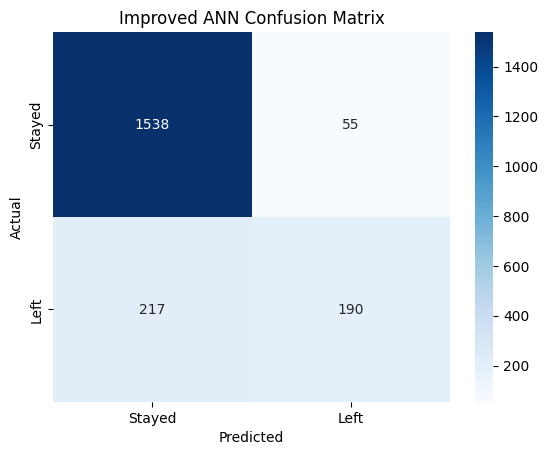

In [9]:
cm = confusion_matrix(y_test, pred2)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Left"],
            yticklabels=["Stayed", "Left"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Improved ANN Confusion Matrix")
plt.show()

## Result

A neural network-based classifier was built to predict whether a bank customer stays or leaves. The basic and improved ANN models were trained and compared using accuracy and confusion matrices.

## Quick Viva Questions

1. **What is customer churn?** When a customer stops using a company's service.
2. **What is ANN?** Artificial Neural Network, a model inspired by interconnected neurons.
3. **What is the target column?** `Exited`.
4. **What does 0 mean?** Customer stayed.
5. **What does 1 mean?** Customer left.
6. **Why split the dataset?** To train the model and test it on unseen data.
7. **Why normalize data?** To put numerical features on a similar scale.
8. **What is an epoch?** One complete pass through the training data.
9. **What is a confusion matrix?** A table showing correct and incorrect predictions.
10. **How did you improve the model?** By using more hidden layers/neurons and early stopping.

**Important:** Accuracy alone can be misleading if the dataset has more customers who stay than customers who leave. Check the confusion matrix to see how many customers who actually left were correctly identified.